# Data Analysis and Preprocessing

This section explores the SMS messages, prepares them for analysis, and compares several sampling strategies. The original `text` column is kept unchanged throughout the notebook.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler #n

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid")

DATA_PATH = Path("../data/dataset.csv")
df = pd.read_csv(DATA_PATH)

print("Loaded", len(df), "rows from", DATA_PATH)

df.head()
#df.label.value_counts()


Loaded 5574 rows from ../data/dataset.csv


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## 1. Understanding the dataset

Each row represents one SMS message. `label` is the category we want to understand and later predict, while `text` contains the message itself. At this stage the dataset has one text column and one categorical label column; the numerical columns are created from the messages below.

In [2]:

print("Shape:", df.shape)

print("Columns:")
print(df.columns)

print("Data Types:")
print(df.dtypes)

print("Dataset Information:")
df.info()

print("Descriptive Statistics:")
display(df.describe(include="all"))

print("Text column: text")
print("Label column: label")


Shape: (5574, 2)
Columns:
Index(['label', 'text'], dtype='str')
Data Types:
label    str
text     str
dtype: object
Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   5574 non-null   str  
 1   text    5574 non-null   str  
dtypes: str(2)
memory usage: 543.0 KB
Descriptive Statistics:


,label,text
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30


Text column: text
Label column: label


## 2. Missing values and duplicates

Missing text cannot be used for text analysis, so those rows will be removed. Missing labels cannot be used as targets, so they will also be removed. Exact duplicate records do not add new information and can bias class counts, so they will be dropped. The before/after shapes make the effect of cleaning explicit.

In [3]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Rows:", df.duplicated().sum())

shape_before = df.shape

df = df.dropna()
df = df.drop_duplicates()
df = df.reset_index(drop=True)

print("Before Cleaning:", shape_before)
print("After Cleaning:", df.shape)
print("Removed Rows:", shape_before[0] - df.shape[0])


Missing Values:
label    0
text     0
dtype: int64
Duplicate Rows: 403
Before Cleaning: (5574, 2)
After Cleaning: (5171, 2)
Removed Rows: 403


## 3. `loc` and `iloc`

`loc` is useful when the selection is based on a condition. `iloc` is useful when the position of the rows or columns is what matters. The `np.r_` example picks rows that are not next to each other. At this point the frame only has `label` and `text`, so the example is on rows.

In [4]:
# Select 5 spam messages
spam_preview = df.loc[df["label"] == "spam", ["label", "text"]]
display(spam_preview.head())

# Select first 3 rows and first 2 columns
display(df.iloc[:3, :2])

# Select first 5 rows
display(df.iloc[:5])

# rows 0 and 1, then skip ahead to rows 10 and 11
display(df.iloc[np.r_[0:2, 10:12]])


,label,text
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs a..."


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
10,ham,"I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today."
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs a..."


## 4. Transformations and feature creation

The following transformations are useful for SMS data: standardizing the label type, consolidating text whitespace, creating several numeric text features, encoding the label, and normalizing message length. The original message remains available in `text`.

In [5]:

df["label"] = df["label"].astype("category")
df["clean_text"] = df["text"].str.strip()
df["char_count"] = df["text"].str.len()
df["word_count"] = df["clean_text"].str.split().str.len()
df["unique_word_count"] = df["clean_text"].str.lower().str.split().apply(lambda x: len(set(x)))
df["avg_word_length"] = df["char_count"] / df["word_count"].clip(lower=1)
df["label_code"] = df["label"].cat.codes
scaler = MinMaxScaler()
df["char_count_normalized"] = scaler.fit_transform(df[["char_count"]]).ravel()
display(df.head())


,label,text,clean_text,char_count,word_count,unique_word_count,avg_word_length,label_code,char_count_normalized
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...","Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",111,20,20,5.550000,0,0.120044
1,ham,Ok lar... Joking wif u oni...,Ok lar... Joking wif u oni...,29,6,6,4.833333,0,0.029736
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,155,28,24,5.535714,1,0.168502
3,ham,U dun say so early hor... U c already then say...,U dun say so early hor... U c already then say...,49,11,10,4.454545,0,0.051762
4,ham,"Nah I don't think he goes to usf, he lives around here though","Nah I don't think he goes to usf, he lives around here though",61,13,12,4.692308,0,0.064978


## 5. Sampling methods

Simple random sampling gives every row the same chance of selection. Stratified sampling preserves the label proportions by sampling within each label. For cluster sampling, messages are grouped into four length-based clusters and two complete clusters are selected. Because clusters are selected as groups, their class balance can differ from the full dataset.

In [6]:
RANDOM_STATE = 42
sample_size = min(500, len(df))

# Simple Random Sampling  كل صف عنده فرصة متساوية للاختيار
simple_sample = df.sample(
    n=sample_size,
    random_state=RANDOM_STATE
)

# Stratified Sampling النوع ده بيحافظ على توزيع الـ Labels.
stratified_sample = df.groupby(
    "label", group_keys=False, observed=True
).sample(
    frac=sample_size / len(df),
    random_state=RANDOM_STATE
)

# Cluster Sampling اختيار مجموعات كاملة ثم أخذ كل الصفوف الموجودة فيها
df["length_cluster"] = pd.qcut(
    df["char_count"],
    q=4,
    labels=["short", "medium", "long", "very long"]
)

clusters = df["length_cluster"].dropna().unique()

chosen_clusters = pd.Series(clusters).sample(
    n=min(2, len(clusters)),
    random_state=RANDOM_STATE
)

cluster_sample = df[
    df["length_cluster"].isin(chosen_clusters)
]

print("Original:", len(df))
print("Simple Random:", len(simple_sample))
print("Stratified:", len(stratified_sample))
print("Cluster:", len(cluster_sample))


Original: 5171
Simple Random: 500
Stratified: 500
Cluster: 2605


,Original,Simple Random,Stratified,Cluster
label,,,,
ham,87.371882,87.8,87.4,99.117083
spam,12.628118,12.2,12.6,0.882917


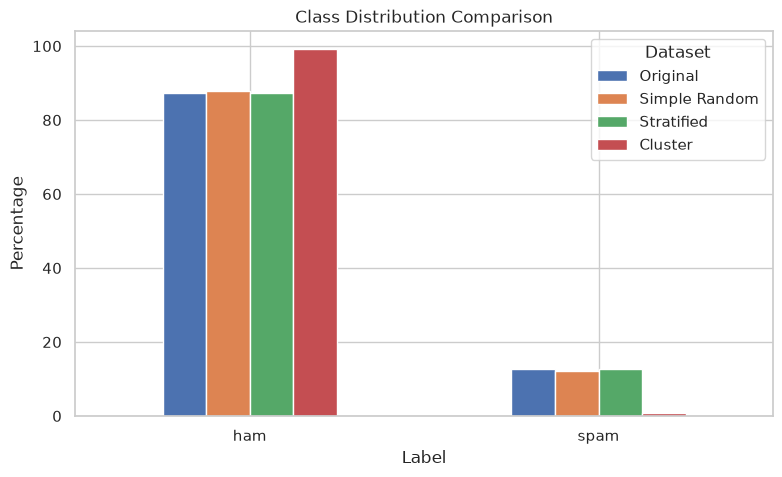

In [7]:

# Calculate label percentages
original = df["label"].value_counts(normalize=True) * 100

simple = simple_sample["label"].value_counts(normalize=True) * 100

stratified = stratified_sample["label"].value_counts(normalize=True) * 100

cluster = cluster_sample["label"].value_counts(normalize=True) * 100

# Combine results
comparison = pd.DataFrame({
    "Original": original,
    "Simple Random": simple,
    "Stratified": stratified,
    "Cluster": cluster
})

display(comparison)

# Plot the results
comparison.plot(kind="bar", figsize=(9, 5))

plt.title("Class Distribution Comparison")
plt.xlabel("Label")
plt.ylabel("Percentage")
plt.xticks(rotation=0)
plt.legend(title="Dataset")
plt.show()


## 6. Correlation between numerical text features

These four text features measure different aspects of a message. `char_count`, `word_count` and `unique_word_count` are the strong pairs, about 0.96 to 0.98. A longer SMS usually has more words, so those counts rise together. `avg_word_length` is the weak one. It stays near 0 with the other three, and it is slightly negative with `word_count`. Correlation does not imply causation. These features are calculated from the same message, so they can move together without one causing the other.

,char_count,word_count,unique_word_count,avg_word_length
char_count,1.000000,0.973673,0.963712,0.131445
word_count,0.973673,1.000000,0.981166,-0.022504
unique_word_count,0.963712,0.981166,1.000000,-0.009806
avg_word_length,0.131445,-0.022504,-0.009806,1.000000


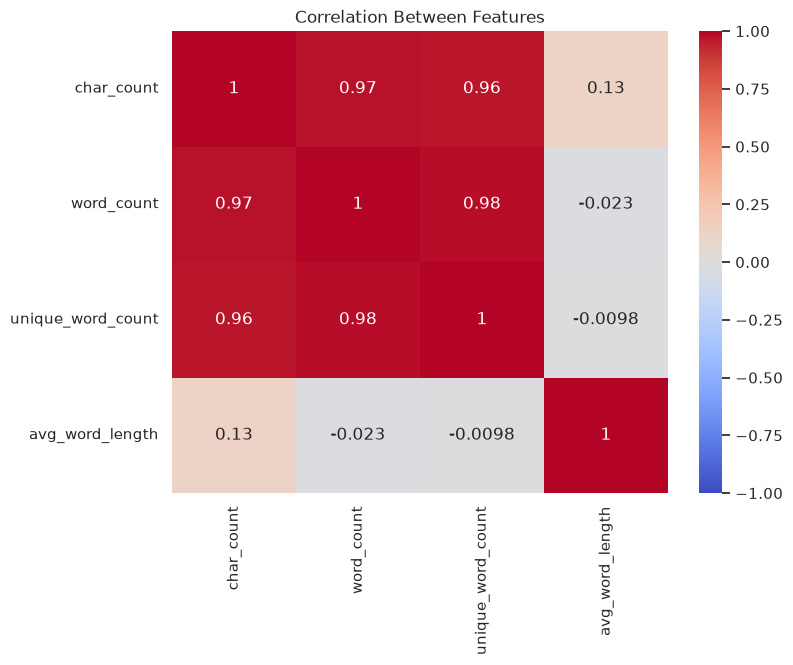

Saved ../output/cleaned_data.csv
Saved ../output/figures/correlation_heatmap.png


In [8]:

numeric_features = [
    "char_count",
    "word_count",
    "unique_word_count",
    "avg_word_length"
]

correlation = df[numeric_features].corr()
display(correlation)
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Features")

output_dir = Path("../output")
figures_dir = output_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

heatmap_path = figures_dir / "correlation_heatmap.png"
plt.savefig(heatmap_path, bbox_inches="tight")
plt.show()

df.to_csv(output_dir / "cleaned_data.csv", index=False)
print("Saved", output_dir / "cleaned_data.csv")
print("Saved", heatmap_path)
